[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/3_leading_eigenvectors_of_G.ipynb)

# Leading eigenvectors of G(x)

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Plot an example image with the receptive fields of the V1 and V4 models, and the leading eigenvectors of G(x) and J(x) (paper Fig. 3D–F).

* **Requirements**: TinyImageNet and the trained checkpoints (downloaded below), and a GPU.

* **Time**: about 2 min.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom` and `diffusers`; elsewhere this does nothing.

time: <1 sec

In [7]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom
    %pip install -q "diffusers>=0.30,<0.38"     # the diffusion model of this notebook

CPU times: user 4 μs, sys: 0 ns, total: 4 μs
Wall time: 5.01 μs


## 2. Import packages and custom functions

### 2.1. Imports and parameters

Work from the repository root, import the packages, and choose the encoders and the example image.

time: <1 sec

In [8]:
%%time

# import built-in packages
import os, sys, subprocess
from pathlib import Path
import torch
import copy, time
import matplotlib.pyplot as plt
from huggingface_hub import snapshot_download
from PIL import Image

# move to the repository root (the folder containing environment.yml): data/ and runs/
# are read from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

sys.path.insert(0, str(root))  # the figures/ folder of this repository
print("repo root:", root)

# import custom package
from multigeom import compute_g, compute_fisher
from multigeom.config import load_config
from multigeom.utils import get_device, make_generator
from multigeom.datasets import (
    CANONICAL_TRANSFORM,
    TinyImageNetDataset,
    download_tinyimagenet,
)

from multigeom.encoders import build_encoder
from multigeom.diffusion.model import build_diffusion_model, build_scheduler
from figures.fig3 import panel_rf, panel_eigvecs
from figures.fig4 import panel_eigvecs as panel_eigvecs_fig4
from figures.style import panel_label

# choose an encoder (and area) to load in section 5, and the encoders to compare in
# section 6
ENC, AREA = "inception", "V1"
ENCODERS = ["inception", "resnet50"]  # onoff checkpoints are not available
AREAS = ["V1", "V4"]

# load the encoder, diffusion and estimator configs (packaged with multigeom)
enc_cfg = load_config(ENC)
diff_cfg = load_config("diffusion")
est_cfg = load_config("estimator")

# choose the image for which to estimate G(x) and J(x): the example image of paper Fig.
# 3D (first TinyImageNet *training* image of the class n01644900, a frog)
IMG_PATH = "data/tiny-imagenet-200/train/n01644900/images/n01644900_0.JPEG"
N_MC = 50  # (default: 200) number of monte carlo samples

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/multigeom-tutorials
device: cuda
CPU times: user 2.59 ms, sys: 34 μs, total: 2.62 ms
Wall time: 2.5 ms


### 2.2. Custom functions

`load_models` loads the encoder and the diffusion model fitted to one encoder and area.

time: <1 sec

In [9]:
%%time


def load_models(enc_name, area):
    """The checkpoint, the encoder and the diffusion model fitted to one area."""
    path = f"runs/encoders/{enc_name}/{area}/best_model.pt"
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    encoder = build_encoder(load_config(enc_name)).to(device)
    encoder.load_state_dict(ckpt["model_state_dict"])
    encoder.eval()

    path = f"runs/diffusion/{enc_name}/{area}/final_model.pt"
    unet = build_diffusion_model(diff_cfg).to(device)
    unet.load_state_dict(
        torch.load(path, map_location=device, weights_only=False)["model_state_dict"]
    )
    unet.eval()
    return ckpt, encoder, unet

CPU times: user 4 μs, sys: 0 ns, total: 4 μs
Wall time: 5.72 μs


## 3. Download trained encoders and diffusion models

The checkpoints (the fitted readouts and the diffusion models) are on Hugging Face. The backbone weights (InceptionV3, ResNet-50) are downloaded by torchvision on first use.

time: 22 secs

In [10]:
%%time

# download the checkpoints into runs/ (files that are already there are kept)
snapshot_download(repo_id="steevelaquitaine/multigeom", local_dir="runs")

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

diffusion/inception/V4/final_model.pt:   0%|          | 0.00/274M [00:00<?, ?B/s]

diffusion/inception/V1/final_model.pt:   0%|          | 0.00/274M [00:00<?, ?B/s]

diffusion/resnet50/V4/final_model.pt:   0%|          | 0.00/274M [00:00<?, ?B/s]

diffusion/resnet50/V1/final_model.pt:   0%|          | 0.00/274M [00:00<?, ?B/s]

.gitattributes: 0.00B [00:00, ?B/s]

README.md:   0%|          | 0.00/656 [00:00<?, ?B/s]

CPU times: user 5.33 s, sys: 3.71 s, total: 9.04 s
Wall time: 22.8 s


'/home/steeve/steeve/idv/code/multigeom-tutorials/runs'

## 4. Download datasets

TinyImageNet gives the example image (240 MB the first time). TVSD and the THINGS images are only needed to refit the encoders, not here.

time: <1 sec

In [11]:
%%time

# TinyImageNet: the example image and the test images (nothing if already there)
download_tinyimagenet()

CPU times: user 175 μs, sys: 73 μs, total: 248 μs
Wall time: 192 μs


PosixPath('/home/steeve/steeve/idv/code/multigeom-tutorials/data/tiny-imagenet-200')

## 5. Load one model pair

Encoder f_φ (frozen backbone + fitted readout) and the conditional diffusion model ε_θ, here for **inception / V1**. Change `ENC` and `AREA` to look at another configuration.

time: <1 secs

In [12]:
%%time 

# encoder
encoder = build_encoder(enc_cfg).to(device)
encoder.load_state_dict(
    torch.load(
        f"runs/encoders/{ENC}/{AREA}/best_model.pt",
        map_location=device,
        weights_only=False,
    )["model_state_dict"]
)

encoder.eval()

# diffusion model
unet = build_diffusion_model(diff_cfg).to(device)
diff_ckpt = torch.load(
    f"runs/diffusion/{ENC}/{AREA}/final_model.pt",
    map_location=device,
    weights_only=False,
)

unet.load_state_dict(diff_ckpt["model_state_dict"])
unet.eval()
scheduler = build_scheduler(diff_cfg)
alphas_cumprod = scheduler.alphas_cumprod.to(device)

# report info
print("diffusion epoch:", diff_ckpt.get("epoch"))

diffusion epoch: 120
CPU times: user 855 ms, sys: 195 ms, total: 1.05 s
Wall time: 665 ms


## 6. Estimate G(x) and J(x), and plot paper Fig. 3D-F and Fig. 4B-C

We estimate G(x) and J(x) for the example image, for Inception and ResNet-50 fitted to V1 and V4, and plot their leading eigenvectors. `N_MC` is the number of Monte-Carlo samples (the paper uses 200, about 15 s per image, encoder and area); use fewer for a quick look. Results are not saved.

<details><summary>Details</summary>

* **Fig. 3D-F** (Inception): the image with the V1 and V4 receptive fields (D), and the leading four eigenvectors of G (E) and of J (F), V1 on top and V4 below.
* **Fig. 4B-C** (Inception and ResNet-50): the leading eigenvectors of G (B) and of J (C) for each architecture, V1 block above the V4 block. The paper also shows the ON-OFF model, for which we have no checkpoints (empty rows).

The plotting functions are in `figures.fig3` and `figures.fig4`.

</details>

### 6.1. Compute

time: 12 secs with `N_MC = 50` (about 1 min with 200)

In [13]:
%%time 

# 1. estimator settings, and the example image
cfg = copy.deepcopy(est_cfg)
cfg.monte_carlo.n_samples = N_MC
sigma = float(cfg.monte_carlo.observation_noise_sigma)

# the example image, [1, 1, 64, 64] in [-1, 1]
x = CANONICAL_TRANSFORM(Image.open(IMG_PATH)).unsqueeze(0).to(device)

# 2. for every encoder and area: load the models, then estimate G(x) and J(x)
# both keyed by (encoder, area): the encoder checkpoint; the image and the eigenpairs
# of G and J
ckpts, records = {}, {}
for enc_name in ENCODERS:
    for area in AREAS:
        # encoder and diffusion model fitted to this area
        ckpts[(enc_name, area)], area_encoder, area_unet = load_models(enc_name, area)

        # G(x) (conditional-pair estimator) and J(x) (closed form)
        g = compute_g(
            image=x,
            encoder=area_encoder,
            unet=area_unet,
            alphas_cumprod=alphas_cumprod,
            cfg=cfg,
            device=device,
            generator=make_generator(int(cfg.seed), device),
        )
        j = compute_fisher(
            image=x,
            encoder=area_encoder,
            sigma=sigma,
            top_k=int(cfg.fisher_baseline.top_k),
            device=device,
        )
        records[(enc_name, area)] = {
            "image": x.cpu(),
            "G_eigenvalues": g.eigenvalues.cpu(),
            "G_eigenvectors": g.eigenvectors.cpu(),
            "J_eigenvalues": j.eigenvalues.cpu(),
            "J_eigenvectors": j.eigenvectors.cpu(),
        }
        print(
            enc_name,
            area,
            "G:",
            tuple(g.eigenvectors.shape),
            " J:",
            tuple(j.eigenvectors.shape),
        )

inception V1 G: (50, 4096)  J: (50, 4096)
inception V4 G: (50, 4096)  J: (50, 4096)
resnet50 V1 G: (50, 4096)  J: (50, 4096)
resnet50 V4 G: (50, 4096)  J: (50, 4096)
CPU times: user 56 s, sys: 3.1 s, total: 59.1 s
Wall time: 15.1 s


### 6.2. Plot leading eigenvectors for inception

These panels correspond to the paper's Fig. 3D-F.

time: <1 sec

<details><summary>Differences with the paper</summary>

* The diffusion checkpoints report epoch 120, not the 200 used for the paper.
* Monte-Carlo noise of the G(x) estimator: seed 42.
* The encoder weight checkpoint may differ from the paper's.

</details>

CPU times: user 520 ms, sys: 2.87 ms, total: 523 ms
Wall time: 69.9 ms


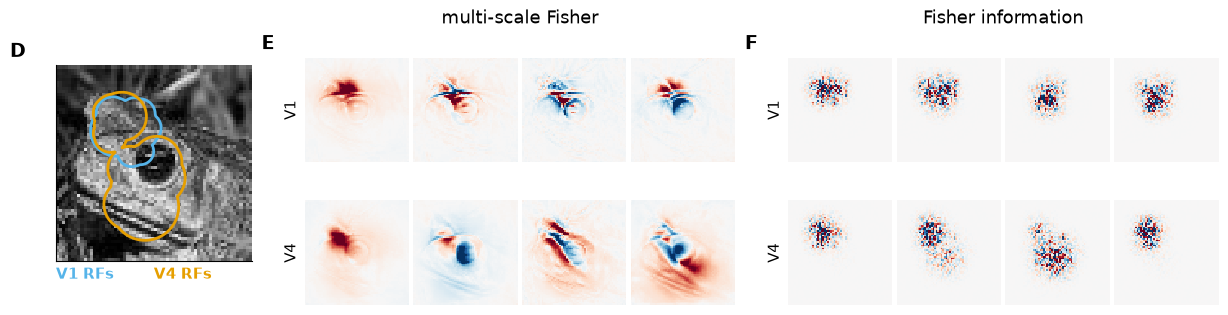

In [14]:
%%time 

# Fig. 3D-F: receptive fields, and leading eigenvectors of G(x) and J(x) for Inception
fig = plt.figure(figsize=(15, 3.9))
spec = fig.add_gridspec(1, 3, width_ratios=[1.0, 2.2, 2.2], wspace=0.15)
ax_d = fig.add_subplot(spec[0])

# D: image with V1 and V4 receptive fields
panel_rf(ax_d, records[(ENC, "V1")]["image"], {a: ckpts[(ENC, a)] for a in AREAS})

# E: leading eigenvectors of G(x); F: those of J(x)
ax_e = panel_eigvecs(fig, spec[1], {a: records[(ENC, a)] for a in AREAS}, "G", 4)
ax_f = panel_eigvecs(fig, spec[2], {a: records[(ENC, a)] for a in AREAS}, "J", 4)
for letter, ax in zip("DEF", (ax_d, ax_e, ax_f)):
    panel_label(fig, ax, letter)

### 6.3. Plot comparison inception vs resnet50

* cf. paper's Fig. 4B-C

For ResNet-50, each displayed eigenvector is the one, among its first 30, that best matches (largest |cosine|) the Inception eigenvector of the same column, with its sign flipped to agree. This only changes the display.

time: <1 sec

CPU times: user 855 ms, sys: 0 ns, total: 855 ms
Wall time: 252 ms


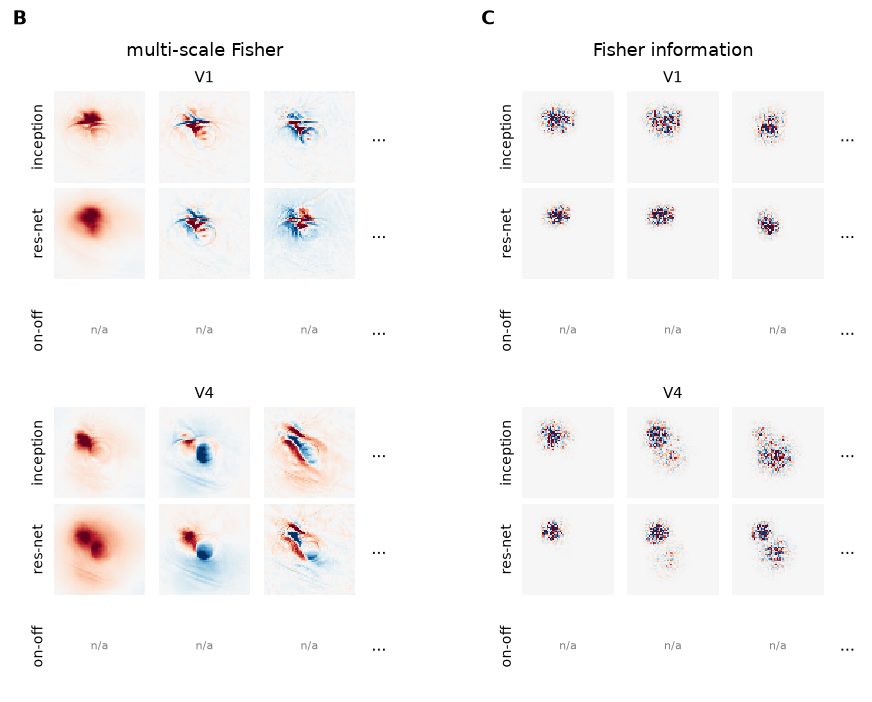

In [15]:
%%time 

# Fig. 4B-C: leading eigenvectors of G(x) and J(x) for each encoder
fig = plt.figure(figsize=(11, 8.5))
spec = fig.add_gridspec(1, 2, wspace=0.22)

# B: leading eigenvectors of G(x), per encoder; C: those of J(x)
ax_b = panel_eigvecs_fig4(fig, spec[0], records, "G", 3, 30)
ax_c = panel_eigvecs_fig4(fig, spec[1], records, "J", 3, 30)
for letter, ax in zip("BC", (ax_b, ax_c)):
    panel_label(fig, ax, letter)